In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import root
from scipy.special import ellipk
from scipy.signal import find_peaks, peak_widths
from scipy.constants import mu_0, epsilon_0
from scipy.optimize import least_squares

In [2]:
!pip install pandas
!pip install resonator_tools

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


In [3]:
import os
os.chdir(r"C:\Users\chowdhf4\.vscode\Tunable-Coupler\TC-Main-001")   # paste your copied path here
print(os.getcwd())
print(os.listdir())  

C:\Users\chowdhf4\.vscode\Tunable-Coupler\TC-Main-001
['TC-ABCD.ipynb', 'TC-Main-001-A-fit-all.mat', 'Tc-Main-001-F-fit-test1.mat', 'TC-Main-001-f0-all.mat', 'TC-Main-001-f0-fit-all.mat', 'TC-Main-001-Fit-v2.ipynb', 'TC-Main-001-Fit-v3.ipynb', 'TC-Main-001-Fit-v4.ipynb', 'TC-Main-001-Fit-v5.ipynb', 'TC-Main-001-Fit-v6.ipynb', 'TC-Main-001-Fit.ipynb', 'TC-Main-001-Freq-Unfiltered.mat', 'TC-Main-001-I-fit-test1.mat', 'TC-Main-001-I1-fit-all.mat', 'TC-Main-001-I1-sp-lp-unfiltered.mat', 'TC-Main-001-Q-ext-fit-all.mat', 'TC-Main-001-Q-int-fit-all.mat', 'TC-Main-001-Q-L-fit-all.mat', 'TC-Main-001-resonator-tools-fit-results.csv', 'TC-Main-001-S21-dB-sp-lp-unfiltered.mat', 'TC-Main-001-S21-Fit-test1.mat', 'TC-Main-001-S21-phase-Fit-test1.mat', 'TC-Main-001-S21-phase-sp-lp-unfiltered.mat']


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import root, least_squares
from scipy.special import ellipk
from scipy.constants import mu_0, epsilon_0
from resonator_tools import  circuit
from scipy.io import loadmat

In [5]:
#natural constants
delta_0 = 1.76*1.38*10**(-23)*1.3
elec_c = 1.602*10**(-19)
phi_0 = 2.067*10**(-15)
h = 6.626*10**(-34)
hbar = h/(2*np.pi)

In [31]:
# Constant values and sweep parameters
N = 2001
M = 501
L01 = 0.09e-9 #1.73333071e-10
L02 = 0.31e-9 #1.73333071e-10
LT = 0.5e-9 # Base value of the josephson junction tunable inductance
R_j = 18 # resistance of the resistor
phi_ext = np.linspace(0*2*np.pi, 1*2*np.pi, M) # for magnetic flux sweep
Z_0 = 50 # characteristic input impedance
#fr = 5e9
f_r = np.linspace(4e9, 5.5e9, N) # for frequency sweep
w_r = 2*np.pi*f_r
C_c = (20e-15)  # coupling capacitance to the transmission line (not shown in the setup)
CT = 5e-15
#Rn = (LT*np.pi*2*delta_0)/hbar

# Solves for the phase difference delta of the josephson junction in the RF SQUID
def del_sol(delta, a, phi_ext_val):
    
    lhs = delta + a * np.sin(delta)
    
    return lhs - phi_ext_val


# calculates the impedance of the coupling capacitor to the transmission line (not shown in the setup)
def c_cap(c_c, w):
    return np.array([[1,1/(1j*c_c*w)],[0,1]])

# calculates the impedance of the resonator
def tline(Z0, beta, L):
    return np.array([[np.cos(beta*L),1j*Z0*np.sin(beta*L)],[1j*(1/Z0)*np.sin(beta*L),np.cos(beta*L)]])


def Z_L(L_01, L_02, L_T, d, w, R):
    #R_n = (L_T*np.pi**2*delta_0)/(elec_c*phi_0)
    ZL01 = 1j*w*L_01
    ZL02 = 1j*w*L_02
    ZLT = 1j*w*L_T/np.cos(d)
    #ZCT = 1/(1j*w*C_T)
    Z_squid = ZLT
    ZL02R = (1/ZL02 + 1/R)**(-1)
    ZSQUID = (1/ZL01 + 1/(Z_squid + ZL02R))**(-1)
    
    return ZSQUID

def Z_tot(ZL, Z0, beta, l, c_c, w):
    x = beta*l
    Z_c = 1/(1j*w*c_c)
    return (Z0*((ZL + 1j*Z0*np.tan(x))/(Z0 + 1j*ZL*np.tan(x)))) + Z_c

def branch(Z):
    return np.array([[1,0], [1/Z, 1]])
    
#calculates the ABCD matrix
def ABCD(M1, M2, M3):
    full_M = M1 @ M2 @ M3 
    
    return full_M
#Calculates the S21 parameter
def S21(A, B, C, D, Z0):
    return 2/(A + B/Z0 + C*Z0 + D)

In [7]:
x = np.array([[1,2],[3,4]])
y = np.zeros((2,2, N))
x.shape
w_r[500]

27488935718.91069

In [32]:
def calc_cpw_param_set(
    center_width: float, gap_width: float, substrate_r: float, metal_thickness: float
):
    a = center_width / 2
    b = center_width / 2 + gap_width
    d = metal_thickness / (2 * np.pi)

    u1 = (
        a
        + d / 2
        + 3 / 2 * np.log(2) * d
        - d / 2 * np.log(d / a)
        + d / 2 * np.log((b - a) / (a + b))
    )
    u2 = (
        b
        - d / 2
        - 3 / 2 * np.log(2) * d
        + d / 2 * np.log(d / a)
        + d / 2 * np.log((b - a) / (a + b))
    )
    k1 = u1 / u2
    k2 = np.sqrt(1 - k1**2)
    c = 2 * epsilon_0 * ellipk(k1) / ellipk(k2) * (1 + substrate_r)

    d = d/2
    u1 = a+d/2+3/2*np.log(2)*d-d/2*np.log(d/a)+d/2*np.log((b-a)/(a+b))
    u2 = b-d/2-3/2*np.log(2)*d+d/2*np.log(d/a)+d/2*np.log((b-a)/(a+b))
    k1 = u1/u2
    k2 = np.sqrt(1-k1**2)
    l = mu_0/4*ellipk(k2)/ellipk(k1)

    lambda_eff = 50e-9  # m, effective field penetration depth
    k = a/b
    g_ctr = 1/(4*a*ellipk(k)**2*(1-k)**2) * \
        (np.pi+np.log(4*np.pi*a/metal_thickness)-k*np.log((1+k)/(1-k)))
    g_gnd = 1/(4*a*ellipk(k)**2*(1-k)**2) * \
        (np.pi+np.log(4*np.pi*b/metal_thickness)-k*np.log((1+k)/(1-k)))
    g = g_ctr+g_gnd
    l_ki = g*mu_0*lambda_eff
    l_tot = l+l_ki

    return {'inductance': l_tot, 'capacitance': c}

def calc_target_length(target_frequency: float, cpw_param_set: dict):
    return 1e6 / (4 * target_frequency * np.sqrt(cpw_param_set['inductance'] * cpw_param_set['capacitance']))



def calc_target_frequency(target_length: float, cpw_param_set: dict):
    return 1e6 / (4 * target_length * np.sqrt(cpw_param_set['inductance'] * cpw_param_set['capacitance']))



resonator_widths = [7, 10, 7]
#################################3

res_cpw_param_set = calc_cpw_param_set(
    center_width= resonator_widths[1]*1e-6, 
    gap_width=resonator_widths[0]*1e-6, 
    substrate_r=11.6, 
    metal_thickness=200e-9
)

l = calc_target_length(5.5e9, res_cpw_param_set)
f = calc_target_frequency(5122.618693762872, res_cpw_param_set)
l_f = l/1e6
L_l = res_cpw_param_set['inductance']
C_l = res_cpw_param_set['capacitance']
R_L = l_f
R_L


0.005122618693766043

In [35]:
res_cpw_param_set['inductance'], res_cpw_param_set['capacitance']

(np.float64(5.074157785774444e-07), np.float64(1.5516958921654493e-10))

In [33]:
TL1 = 2e-3 # first part of the transmission line
TL2 = 15e-3 # second part of the transmission line
I1 = np.eye(2)
I2 = np.eye(2)
RL = l_f
# storage arrays
delta_sols = np.zeros(M)
delta_sols[0] = phi_ext[0]
ZL_vals = np.zeros((N,M), dtype = complex)
#ZL_1_vals = np.zeros(N, dtype = complex)
#ZL_2_vals = np.zeros(N, dtype = complex)
#ZC_vals = np.zeros((2,2,N),  dtype = complex)
#Z_tline_vals_1 = np.zeros((2,2,N),  dtype = complex)
#Z_tline_vals_2 = np.zeros((2,2,N),  dtype = complex)
Z_tot_vals = np.zeros((N,M), dtype = complex)
Z_branch_vals = np.zeros((2,2,N,M), dtype = complex)
fullM_vals = np.zeros((2,2,N,M), dtype = complex)
beta_vals = np.zeros(N)
#Res = np.array([[1,0],[1/R_j,1]])
S21_vals = np.zeros((N,M), dtype = complex)

# for loop for calculating the phase difference for each flux
for k in range(1, M):
    d0 = delta_sols[k-1]
    L_f = ((L01+L02)/LT)
    sol = root(del_sol, d0, args=(L_f, phi_ext[k]))
    delta_sols[k] = sol.x[0]
        
# for loop to calculate S21 for each flux and frequency value
for i in range(N):
    beta_vals[i] = w_r[i] * np.sqrt(L_l*C_l)
    #ZC_vals[:, :, i] = c_cap(C_c, w_r[i])
    #Z_tline_vals_1[:, :, i] = tline(Z_0, beta_vals[i], TL1)
    #Z_tline_vals_2[:, :, i] = tline(Z_0, beta_vals[i], TL2)
    for j in range(M):  
        ZL_vals[i, j] = Z_L(L01, L02, LT, delta_sols[j], w_r[i], R_j)
        Z_tot_vals[i, j] = Z_tot(ZL_vals[i, j], Z_0, beta_vals[i], RL, C_c, w_r[i])
        Z_branch_vals[:, :, i, j] = branch(Z_tot_vals[i,j])
        #fullM_vals[:, :, i, j] = ABCD(Z_tline_vals_1[:, :, i], Z_branch_vals[:, :, i, j], Z_tline_vals_2[:, :, i])
        fullM_vals[:, :, i, j] = ABCD(I1, Z_branch_vals[:, :, i, j], I2)
        S21_vals[i, j] = S21(fullM_vals[0, 0, i, j], fullM_vals[0, 1, i, j], fullM_vals[1, 0, i, j], fullM_vals[1, 1, i, j], Z_0)

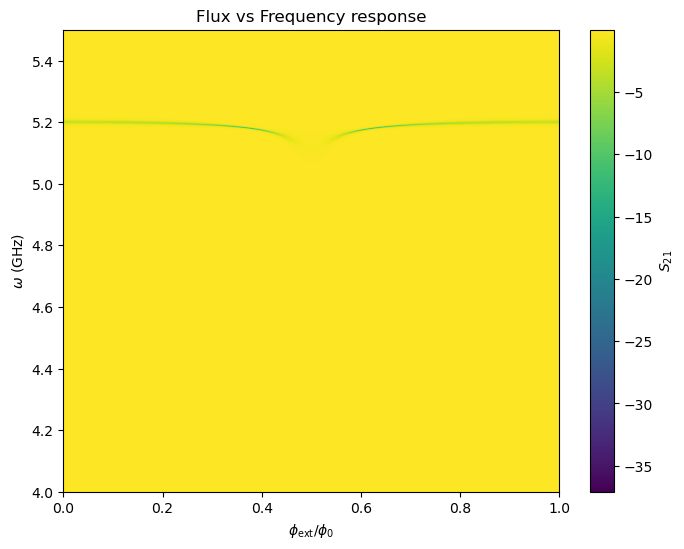

In [34]:
plt.figure(figsize=(8, 6))
plt.imshow(20*np.log10(np.abs(S21_vals)), extent = [0, 1, 4, 5.5], origin='lower', aspect='auto', cmap='viridis')
plt.colorbar(label=r'$S_{21}$')
plt.xlabel(r'$\phi_{\rm ext} / \phi_0$')
plt.ylabel(r'$\omega$ (GHz)')
plt.title(r'Flux vs Frequency response')

plt.show()

In [35]:
x = 20*np.log10(np.abs(S21_vals[:, 0:250]))
y = 20*np.log10(np.abs(S21_vals[:, 251:500]))
idx_flat = np.argmin(x)                # index in flattened array
idx_flat_2 = np.argmin(y)
i_max, j_max = np.unravel_index(idx_flat, x.shape)  # 2D indices
i_max_2, j_max_2 = np.unravel_index(idx_flat_2, y.shape)
#max_value = x[i_max, j_max]
i_max, j_max, i_max_2, j_max_2, C_c

(1574, 190, 1574, 59, 2e-14)

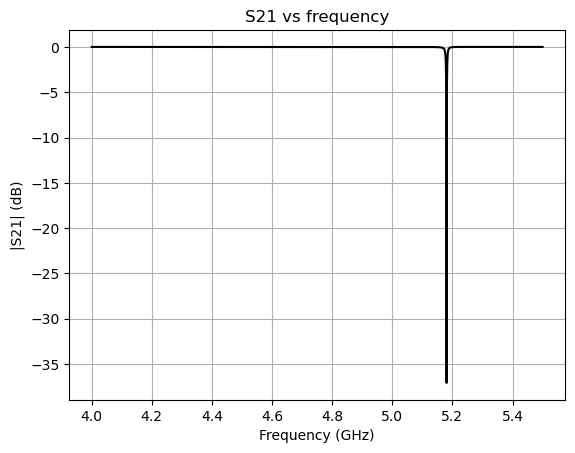

In [36]:
#j0 = np.argmin(np.abs(phi_ext - np.pi))
S21_zero_flux = S21_vals[:, j_max]  # shape (N,)
S21_shallow_flux = S21_vals[:, j_max+70] 
freq = w_r/(2*np.pi)  # your frequency array in Hz

plt.figure()
plt.plot(freq*1e-9, 20*np.log10(np.abs(S21_zero_flux)), 'k', label = 'high')
#plt.plot(freq*1e-9, 20*np.log10(np.abs(S21_shallow_flux)), 'r', label = 'low')
plt.xlabel('Frequency (GHz)')
#plt.xlabel(r'$\phi_{\rm ext}/\phi_{0}$')
plt.ylabel('|S21| (dB)')
plt.title(r'S21 vs frequency')
#plt.legend()
plt.grid(True)
#x = np.abs(S21_vals[


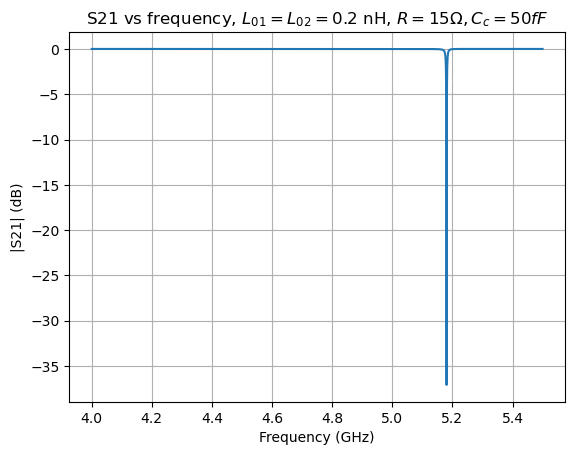

In [37]:
S21_shallow_flux = S21_vals[:, j_max]  # shape (N,)
freq = w_r/(2*np.pi)  # your frequency array in Hz

plt.figure()
plt.plot(freq*1e-9, 20*np.log10(np.abs(S21_shallow_flux)))
plt.xlabel('Frequency (GHz)')
#plt.xlabel(r'$\phi_{\rm ext}/\phi_{0}$')
plt.ylabel('|S21| (dB)')
plt.title(r'S21 vs frequency, $L_{01} = L_{02} = 0.2$ nH, $R = 15 \Omega, C_c = 50 fF$')
plt.grid(True)

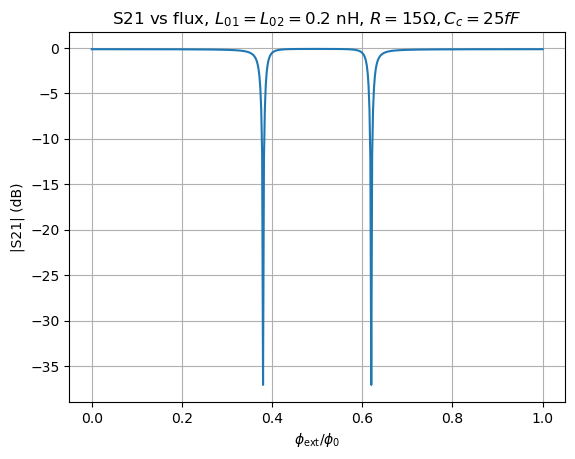

In [38]:
S21_zero_flux = S21_vals[i_max, :]  # shape (N,)
freq = w_r/(2*np.pi)  # your frequency array in Hz

plt.figure()
plt.plot(phi_ext/(2*np.pi), 20*np.log10(np.abs(S21_zero_flux)))
plt.xlabel(r'$\phi_{\rm ext} / \phi_0$')
#plt.xlabel(r'$\phi_{\rm ext}/\phi_{0}$')
plt.ylabel('|S21| (dB)')
plt.title(r'S21 vs flux, $L_{01} = L_{02} = 0.2$ nH, $R = 15 \Omega, C_c = 25 fF$')
plt.grid(True)

In [39]:
from scipy.optimize import curve_fit
def lorentzian_dip_power(f, f0, Q_L, baseline, Q_e_inv):
    """
    Fit model for |S21|^2 in terms of Q factors directly.
    Q_e_inv = 1/Q_e (easier to fit as a free parameter)
    """
    depth_amplitude = Q_L * Q_e_inv          # = Q_L / Q_e
    lorentz = depth_amplitude / (1 + 4 * Q_L**2 * ((f - f0)/f0)**2)
    # |S21|^2 = baseline * |1 - lorentz|^2
    return baseline * (1 - lorentz)**2


def calculate_q_factors(freq, S21_vals):

    # Ensure freq is a flat 1D array
    #freq = np.asarray(freq).flatten()
    n_flux = S21_vals.shape[1]
    
    q_loaded = np.zeros(n_flux)
    q_internal = np.zeros(n_flux)
    q_external = np.zeros(n_flux)
    f0_fits = np.zeros(n_flux)
    
    for i in range(n_flux):
        power = np.abs(S21_vals[:, i])**2
        
        baseline_guess = np.max(power)
        min_idx = np.argmin(power)
        f0_guess = freq[min_idx]
        S21_min = np.sqrt(power[min_idx] / baseline_guess)
        
        # Estimate df (FWHM) by finding points below the half-depth
        half_max = baseline_guess - (baseline_guess - power[min_idx]) / 2.0
        below_half = np.where(power < half_max)[0]
        
        df_guess = freq[below_half[-1]] - freq[below_half[0]]

        Q_L_guess = f0_guess/df_guess
        
        dip = np.clip(1.0-S21_min, 1e-6, 2.0)
        Qe_inv_guess = dip/Q_L_guess
                 
        p0 = [f0_guess, Q_L_guess, baseline_guess, Qe_inv_guess]
        
        popt, _ = curve_fit(lorentzian_dip_power, freq, power,
                            p0=p0, maxfev=10000)
        f0_fit, Q_L_fit, _, Qe_inv_fit = popt
        Q_L_fit = np.abs(Q_L_fit)
        Q_e_fit = 1.0 / np.abs(Qe_inv_fit)
        
        Q_i_fit = 1.0 / (1.0/Q_L_fit - 1.0/Q_e_fit)

        q_loaded[i]   = Q_L_fit
        q_external[i] = Q_e_fit
        q_internal[i] = Q_i_fit
        f0_fits[i]    = f0_fit

    return q_loaded, q_internal, q_external, f0_fits


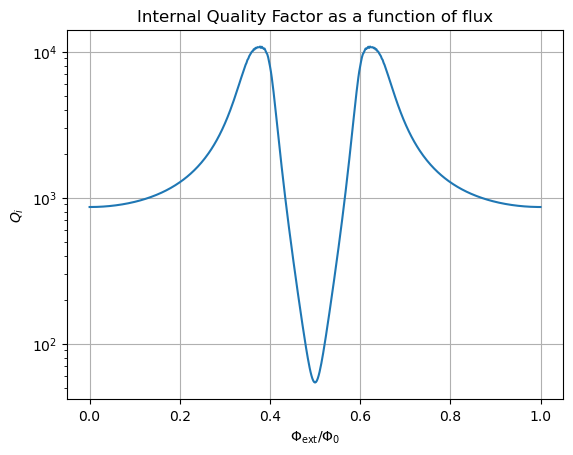

In [40]:
q_L, q_i, q_e, f0_array = calculate_q_factors(freq, S21_vals)
plt.semilogy(phi_ext/(2*np.pi), q_i)
plt.xlabel(r'$\Phi_{\rm ext}/\Phi_0$')
plt.ylabel(r'$Q_{i}$')
plt.title(r"Internal Quality Factor as a function of flux")
plt.grid(True)
#plt.legend()
plt.show()

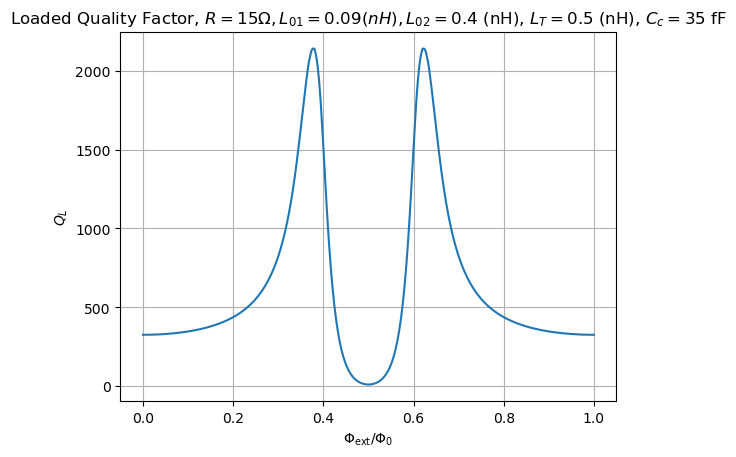

(-118.2831464729194, 5.023540743230551, 11.261232802925567)

In [27]:
plt.plot(phi_ext/(2*np.pi), q_L)
plt.xlabel(r'$\Phi_{\rm ext}/\Phi_0$')
plt.ylabel(r'$Q_{L}$')
plt.title(r"Loaded Quality Factor, $R = 15\Omega, L_{01} = 0.09 (nH), L_{02} = 0.4$ (nH), $L_T = 0.5$ (nH), $C_c = 35$ fF")
plt.grid(True)
#plt.legend()
plt.show()
Gamma_10 = (f0_array[379]/q_L[np.argmin(q_L)])
P_p = 1 * 6.626 * 10**(-34) * f0_array[379] * Gamma_10
10*np.log10(P_p*1000), f0_array[379]/1e9, np.min(q_L)

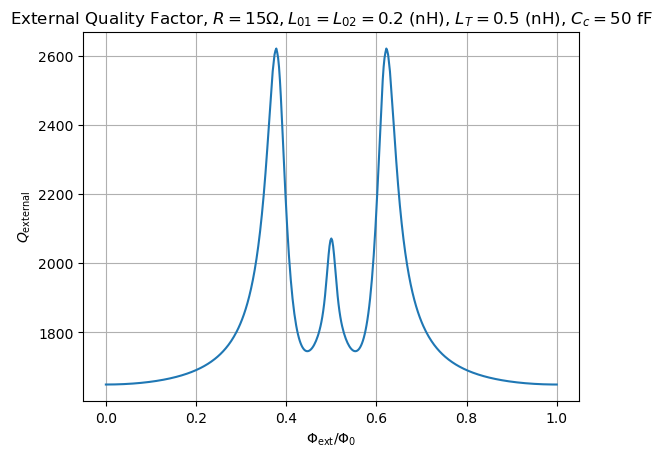

In [28]:
plt.plot(phi_ext/(2*np.pi), q_e)
plt.xlabel(r'$\Phi_{\rm ext}/\Phi_0$')
plt.ylabel(r'$Q_{\rm external}$')
plt.title(r"External Quality Factor, $R = 15\Omega, L_{01} = L_{02} = 0.2$ (nH), $L_T = 0.5$ (nH), $C_c = 50$ fF")
plt.grid(True)
#plt.legend()
plt.show()

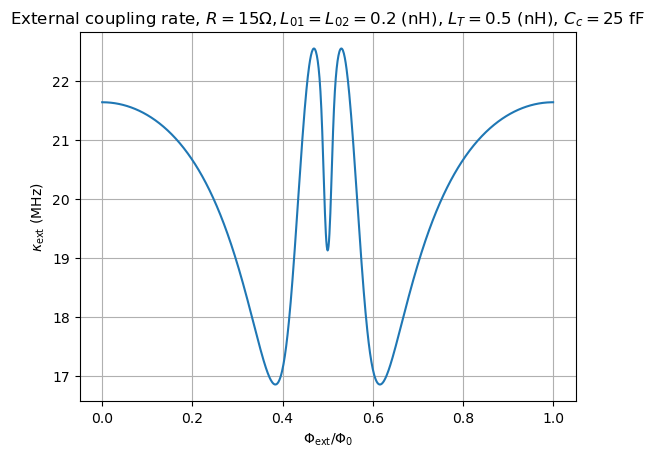

In [20]:
plt.plot(phi_ext/(2*np.pi), ((f0_array)/(q_e))/1e6)
plt.xlabel(r'$\Phi_{\rm ext}/\Phi_0$')
plt.ylabel(r'$\kappa_{\rm ext}$ (MHz)')
plt.title(r"External coupling rate, $R = 15\Omega, L_{01} = L_{02} = 0.2$ (nH), $L_T = 0.5$ (nH), $C_c = 25$ fF")
plt.grid(True)
#plt.legend()
plt.show()

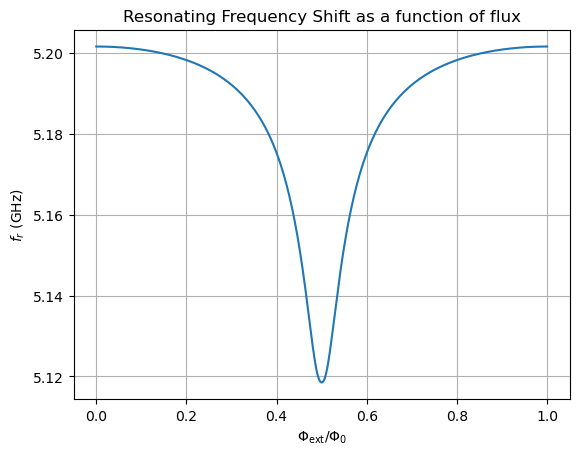

In [41]:
plt.plot(phi_ext/(2*np.pi), f0_array/1e9, label = r'$R = 20\Omega$')
plt.xlabel(r'$\Phi_{\rm ext}/\Phi_0$')
plt.ylabel(r'$f_r$ (GHz)')
plt.title(r"Resonating Frequency Shift as a function of flux")
plt.grid(True)
plt.show()

In [40]:
mat_data_s21 = loadmat('TC-Main-001-S21-Fit-test1.mat', squeeze_me=True)
mat_data_freq = loadmat('Tc-Main-001-F-fit-test1.mat', squeeze_me=True)
mat_data_current = loadmat('TC-Main-001-I-fit-test1.mat', squeeze_me = True)
mat_data_f0 = loadmat('TC-Main-001-f0-fit-all.mat', squeeze_me = True)
mat_data_I1 = loadmat('TC-Main-001-I1-fit-all.mat', squeeze_me = True)
mat_data_Q_ext = loadmat('TC-Main-001-Q-ext-fit-all.mat', squeeze_me = True)
mat_data_Q_L = loadmat('TC-Main-001-Q-L-fit-all.mat', squeeze_me = True)
mat_data_Q_int = loadmat('TC-Main-001-Q-int-fit-all.mat', squeeze_me = True)

In [41]:
S21_dB = mat_data_s21['S21_fit'] 
Freq = mat_data_freq['F_fit']
I1_data = mat_data_current['I_fit']
f0_all = mat_data_f0['f0_all']
I1_all = mat_data_I1['I1_all']
Q_ext_all = mat_data_Q_ext['Qext_all']
Q_L_all = mat_data_Q_L['QL_all']
Q_int_all = mat_data_Q_int['Qi_all']

I_plot_uA = np.linspace(I1_all.min(), I1_all.max(), 1001)
I_plot_A = I_plot_uA * 1e-6

In [42]:
L01 = 0.3e-9 #1.73333071e-10
L02 = 0.3e-9 #1.73333071e-10
LT = 0.61e-9
R_vals = np.linspace(5, 50, 10)
N_R = len(R_vals)
C_c = (11e-15)  # coupling capacitance to the transmission line (not shown in the setup)
delta_sols_R = np.zeros((N))
delta_sols_R[0] = phi_ext[0]
ZL_vals_R = np.zeros((N,N,N_R), dtype = complex)
phi_ext = np.linspace(0, 2*np.pi, N)
f_r = np.linspace(3.8e9, 5e9, N) # for frequency sweep
w_r = 2*np.pi*f_r
Z_tot_vals_R = np.zeros((N,N,N_R), dtype = complex)
Z_branch_vals_R = np.zeros((2,2,N,N,N_R), dtype = complex)
fullM_vals_R = np.zeros((2,2,N,N,N_R), dtype = complex)
beta_vals_R = np.zeros(N)
#Res = np.array([[1,0],[1/R_j,1]])
S21_vals_R = np.zeros((N,N,N_R), dtype = complex)

# for loop for calculating the phase difference for each flux and frequency
for k in range(1, N):
    d0 = delta_sols_R[k-1]
    L_f = ((L01+L02)/LT)
    sol = root(del_sol, d0, args=(L_f, phi_ext[k]))
    delta_sols_R[k] = sol.x[0]
        
# for loop to calculate S21 for each flux and frequency value
for i in range(N):
    beta_vals_R[i] = w_r[i] * np.sqrt(L_l*C_l)
    #ZC_vals[:, :, i] = c_cap(C_c, w_r[i])
    #Z_tline_vals_1[:, :, i] = tline(Z_0, beta_vals[i], TL1)
    #Z_tline_vals_2[:, :, i] = tline(Z_0, beta_vals[i], TL2)
    for j in range(N):
        for k in range(N_R):
            ZL_vals_R[i, j, k] = Z_L(L01, L02, LT, CT, delta_sols_R[j], w_r[i], R_vals[k])
            Z_tot_vals_R[i, j, k] = Z_tot(ZL_vals_R[i, j, k], Z_0, beta_vals_R[i], RL, C_c, w_r[i])
            Z_branch_vals_R[:, :, i, j, k] = branch(Z_tot_vals_R[i,j, k])
            #fullM_vals[:, :, i, j] = ABCD(Z_tline_vals_1[:, :, i], Z_branch_vals[:, :, i, j], Z_tline_vals_2[:, :, i])
            fullM_vals_R[:, :, i, j, k] = ABCD(I1, Z_branch_vals_R[:, :, i, j, k], I2)
            S21_vals_R[i, j, k] = S21(fullM_vals_R[0, 0, i, j, k], fullM_vals_R[0, 1, i, j, k], fullM_vals_R[1, 0, i, j, k], fullM_vals_R[1, 1, i, j, k], Z_0)

In [11]:
q_loaded_array_R = np.zeros((N,N_R))
q_external_array_R = np.zeros((N,N_R))
q_internal_array_R = np.zeros((N,N_R))
f0_array_R = np.zeros((N,N_R))

for i in range(N_R):
    q_loaded_array_R[:, i], q_internal_array_R[:, i], q_external_array_R[:, i], f0_array_R[:, i] =  calculate_q_factors(f_r, S21_vals_R[:, :, i])


<>:2: SyntaxWarning: invalid escape sequence '\O'
<>:2: SyntaxWarning: invalid escape sequence '\O'
C:\Users\chowdhf4\AppData\Local\Temp\ipykernel_7188\812947000.py:2: SyntaxWarning: invalid escape sequence '\O'
  plt.plot(phi_ext/(2*np.pi), f0_array_R[:,i], label = f'$R = {R_vals[i]} \Omega$')


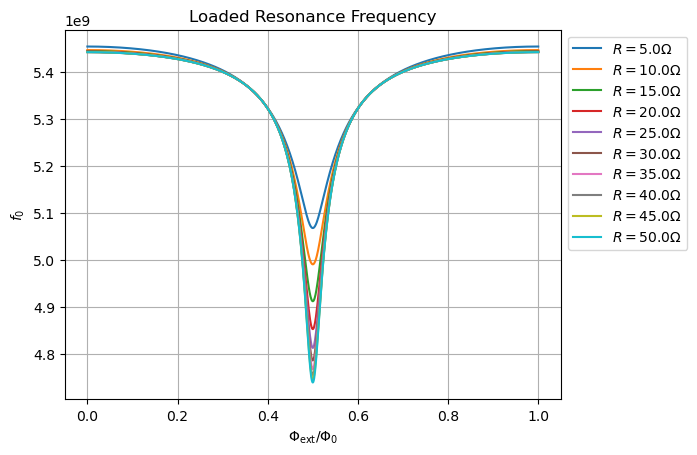

In [17]:
for i in range(len(R_vals)):
    plt.plot(phi_ext/(2*np.pi), f0_array_R[:,i], label = f'$R = {R_vals[i]} \Omega$')
    
plt.xlabel(r'$\Phi_{\rm ext}/\Phi_0$')
plt.ylabel(r'$f_0$')
plt.title(r"Loaded Resonance Frequency")
plt.grid(True)
plt.legend(loc = 'upper left', bbox_to_anchor=(1, 1))
plt.show()

<>:2: SyntaxWarning: invalid escape sequence '\O'
<>:2: SyntaxWarning: invalid escape sequence '\O'
C:\Users\chowdhf4\AppData\Local\Temp\ipykernel_18820\419392590.py:2: SyntaxWarning: invalid escape sequence '\O'
  plt.plot(phi_ext/(2*np.pi), q_loaded_array_R[:,i], label = f'$R = {R_vals[i]} \Omega$')


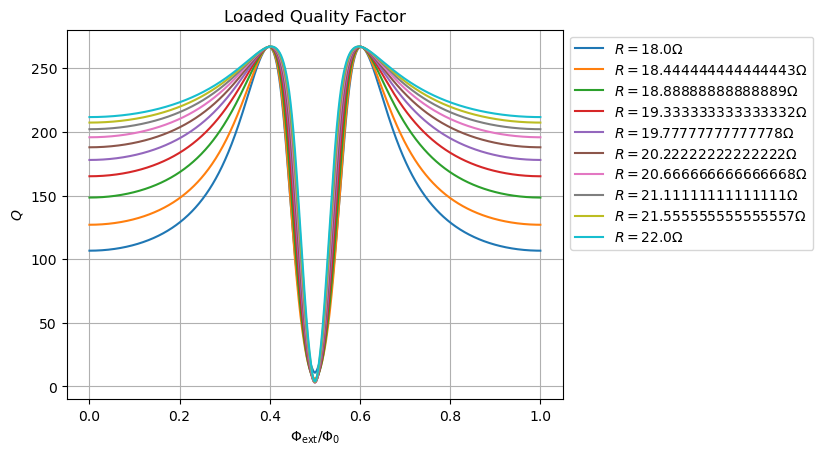

In [50]:
for i in range(len(R_vals)):
    plt.plot(phi_ext/(2*np.pi), q_loaded_array_R[:,i], label = f'$R = {R_vals[i]} \Omega$')
    
plt.xlabel(r'$\Phi_{\rm ext}/\Phi_0$')
plt.ylabel(r'$Q$')
plt.title(r"Loaded Quality Factor")
plt.grid(True)
plt.legend(loc = 'upper left', bbox_to_anchor=(1, 1))
plt.show()

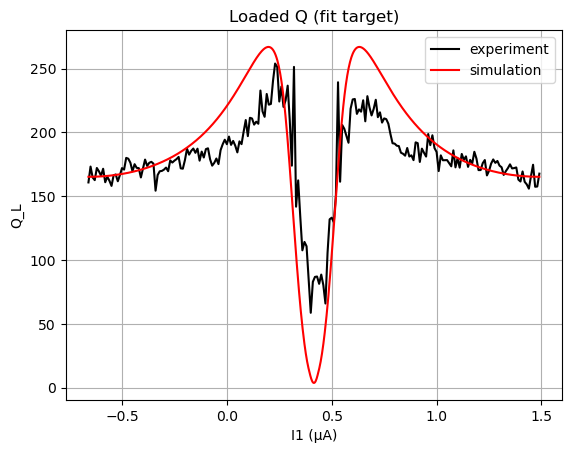

In [56]:
plt.plot(I1_all, Q_L_all, 'k', label = 'experiment')
plt.plot(I_plot_uA, q_loaded_array_R[:, 3], 'r', label = 'simulation')
plt.xlabel('I1 (μA)')
plt.ylabel('Q_L')
plt.title('Loaded Q (fit target)')
plt.legend()
plt.grid(True)
plt.show()

In [26]:
# storage arrays
N = 1001
L01 = 0.16e-9
L02 = 0.16e-9
LT_vals = np.linspace(0.33e-9, 0.4e-9, 10)
N_L = len(LT_vals)
C_c = 35e-15  # coupling capacitance to the transmission line (not shown in the setup)
R_j = 18
C_T = 5e-15
delta_sols_LT = np.zeros((N, N_L))
delta_sols_LT[0, :] = phi_ext[0]
ZL_vals_LT = np.zeros((N,N,N_L), dtype = complex)
phi_ext = np.linspace(0, 2*np.pi, N)
f_r = np.linspace(4e9, 5.6e9, N) # for frequency sweep
w_r = 2*np.pi*f_r
Z_tot_vals_LT = np.zeros((N,N,N_L), dtype = complex)
Z_branch_vals_LT = np.zeros((2,2,N,N,N_L), dtype = complex)
fullM_vals_LT = np.zeros((2,2,N,N,N_L), dtype = complex)
beta_vals_LT = np.zeros(N)
#Res = np.array([[1,0],[1/R_j,1]])
S21_vals_LT = np.zeros((N,N,N_L), dtype = complex)

# for loop for calculating the phase difference for each flux and frequency
for k in range(1, N):
    for l in range(N_L):
        d0 = delta_sols_LT[k-1, l]
        L_f = ((L01+L02)/LT_vals[l])
        sol = root(del_sol, d0, args=(L_f, phi_ext[k]))
        delta_sols_LT[k, l] = sol.x[0]
        
# for loop to calculate S21 for each flux and frequency value
for i in range(N):
    beta_vals_LT[i] = w_r[i] * np.sqrt(L_l*C_l)
    #ZC_vals[:, :, i] = c_cap(C_c, w_r[i])
    #Z_tline_vals_1[:, :, i] = tline(Z_0, beta_vals[i], TL1)
    #Z_tline_vals_2[:, :, i] = tline(Z_0, beta_vals[i], TL2)
    for j in range(N):
        for k in range(N_L):
            ZL_vals_LT[i, j, k] = Z_L(L01, L02, LT_vals[k], C_T, delta_sols_LT[j, k], w_r[i], R_j)
            Z_tot_vals_LT[i, j, k] = Z_tot(ZL_vals_LT[i, j, k], Z_0, beta_vals_LT[i], RL, C_c, w_r[i])
            Z_branch_vals_LT[:, :, i, j, k] = branch(Z_tot_vals_LT[i,j, k])
            #fullM_vals[:, :, i, j] = ABCD(Z_tline_vals_1[:, :, i], Z_branch_vals[:, :, i, j], Z_tline_vals_2[:, :, i])
            fullM_vals_LT[:, :, i, j, k] = ABCD(I1, Z_branch_vals_LT[:, :, i, j, k], I2)
            S21_vals_LT[i, j, k] = S21(fullM_vals_LT[0, 0, i, j, k], fullM_vals_LT[0, 1, i, j, k], fullM_vals_LT[1, 0, i, j, k], fullM_vals_LT[1, 1, i, j, k], Z_0)

In [27]:
q_loaded_array_LT = np.zeros((N,N_L))
q_external_array_LT = np.zeros((N,N_L))
q_internal_array_LT = np.zeros((N,N_L))
f0_array_LT = np.zeros((N,N_L))

for i in range(N_L):
    q_loaded_array_LT[:, i], q_internal_array_LT[:, i], q_external_array_LT[:, i], f0_array_LT[:, i] = calculate_q_factors(f_r, S21_vals_LT[:, :, i])

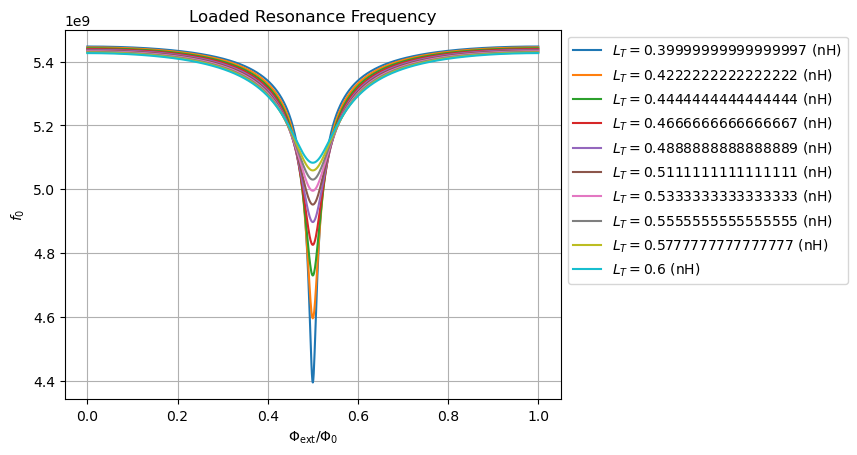

In [21]:
for i in range(len(LT_vals)):
    plt.plot(phi_ext/(2*np.pi), f0_array_LT[:,i], label = f'$L_T = {LT_vals[i]/1e-9}$ (nH)')
    
plt.xlabel(r'$\Phi_{\rm ext}/\Phi_0$')
plt.ylabel(r'$f_0$')
plt.title(r"Loaded Resonance Frequency")
plt.grid(True)
plt.legend(loc = 'upper left', bbox_to_anchor=(1, 1))
plt.show()
#np.min(q_loaded_array)

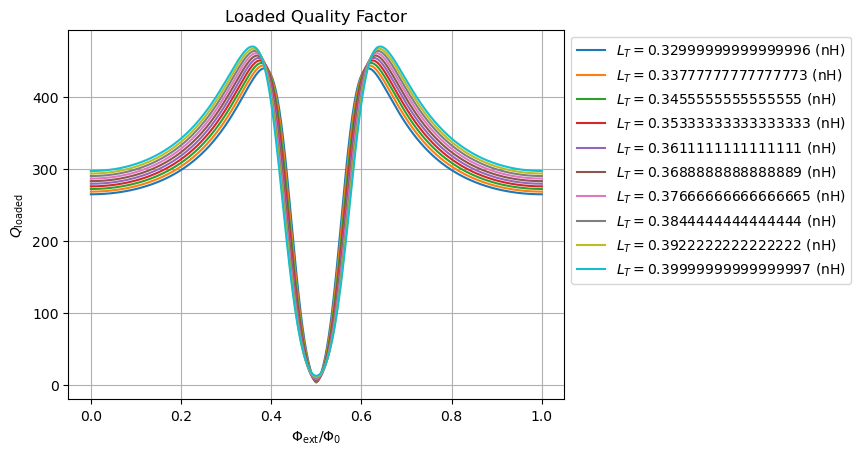

In [28]:
for i in range(len(LT_vals)):
    plt.plot(phi_ext/(2*np.pi), q_loaded_array_LT[:,i], label = f'$L_T = {LT_vals[i]/1e-9}$ (nH)')
    
plt.xlabel(r'$\Phi_{\rm ext}/\Phi_0$')
plt.ylabel(r'$Q_{\rm loaded}$')
plt.title(r"Loaded Quality Factor")
plt.grid(True)
plt.legend(loc = 'upper left', bbox_to_anchor=(1, 1))
plt.show()

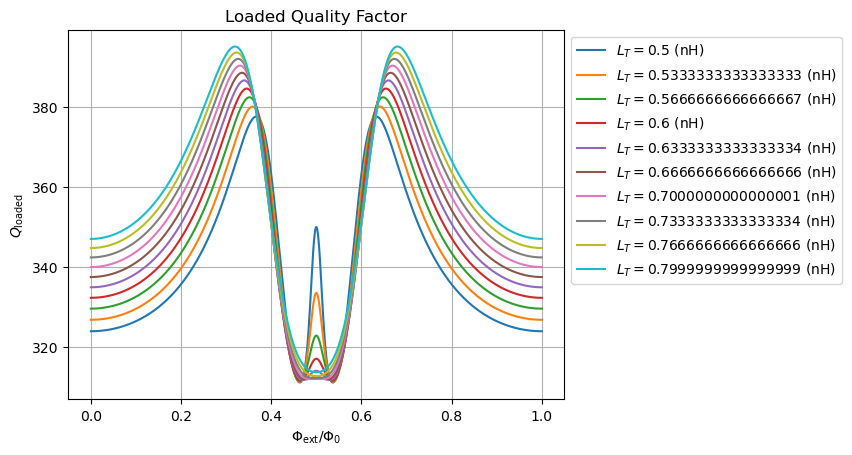

In [21]:
for i in range(len(LT_vals)):
    plt.plot(phi_ext/(2*np.pi), q_external_array_LT[:,i], label = f'$L_T = {LT_vals[i]/1e-9}$ (nH)')
    
plt.xlabel(r'$\Phi_{\rm ext}/\Phi_0$')
plt.ylabel(r'$Q_{\rm loaded}$')
plt.title(r"Loaded Quality Factor")
plt.grid(True)
plt.legend(loc = 'upper left', bbox_to_anchor=(1, 1))
plt.show()

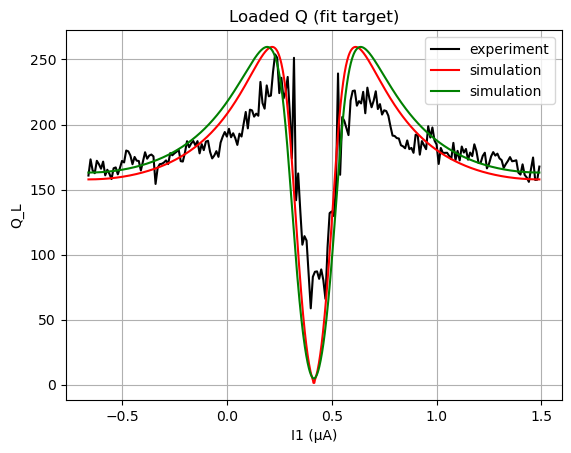

In [76]:
plt.plot(I1_all, Q_L_all, 'k', label = 'experiment')
plt.plot(I_plot_uA, q_loaded_array_LT[:, 0], 'r', label = 'simulation')
plt.plot(I_plot_uA, q_loaded_array_LT[:, 1], 'g', label = 'simulation')
plt.xlabel('I1 (μA)')
plt.ylabel('Q_L')
plt.title('Loaded Q (fit target)')
plt.legend()
plt.grid(True)
plt.show()

In [87]:
N = 1001
L01_vals = [0.02e-9, 0.04e-9, 0.06e-9, 0.08e-9, 0.1e-9, 0.12e-9, 0.14e-9]
LT    = 0.45e-9
L02 = 0.3e-9
N_L1 = len(L01_vals)
R_L = l_f
C_c = (35e-15)  # coupling capacitance to the transmission line (not shown in the setup)
R_j = 20
delta_sols_L01 = np.zeros((N, N_L1))
delta_sols_L01[0, :] = phi_ext[0]
ZL_vals_L01 = np.zeros((N,N,N_L1), dtype = complex)
phi_ext = np.linspace(0, 2*np.pi, N)
f_r = np.linspace(4e9, 5.6e9, N) # for frequency sweep
w_r = 2*np.pi*f_r
Z_tot_vals_L01 = np.zeros((N,N,N_L1), dtype = complex)
Z_branch_vals_L01 = np.zeros((2,2,N,N,N_L1), dtype = complex)
fullM_vals_L01 = np.zeros((2,2,N,N,N_L1), dtype = complex)
beta_vals_L01 = np.zeros(N)
#Res = np.array([[1,0],[1/R_j,1]])
S21_vals_L01 = np.zeros((N,N,N_L1), dtype = complex)

# for loop for calculating the phase difference for each flux and frequency
for k in range(1, N):
    for l in range(N_L1):
        d0 = delta_sols_L01[k-1, l]
        L_f = ((L01_vals[l]+L02)/LT)
        sol = root(del_sol, d0, args=(L_f, phi_ext[k]))
        delta_sols_L01[k, l] = sol.x[0]
        
# for loop to calculate S21 for each flux and frequency value
for i in range(N):
    beta_vals_L01[i] = w_r[i] * np.sqrt(L_l*C_l)
    #ZC_vals[:, :, i] = c_cap(C_c, w_r[i])
    #Z_tline_vals_1[:, :, i] = tline(Z_0, beta_vals[i], TL1)
    #Z_tline_vals_2[:, :, i] = tline(Z_0, beta_vals[i], TL2)
    for j in range(N):
        for k in range(N_L1):
            ZL_vals_L01[i, j, k] = Z_L(L01_vals[k], L02, LT, delta_sols_L01[j, k], w_r[i], R_j)
            Z_tot_vals_L01[i, j, k] = Z_tot(ZL_vals_L01[i, j, k], Z_0, beta_vals_L01[i], R_L, C_c, w_r[i])
            Z_branch_vals_L01[:, :, i, j, k] = branch(Z_tot_vals_L01[i,j, k])
            #fullM_vals[:, :, i, j] = ABCD(Z_tline_vals_1[:, :, i], Z_branch_vals[:, :, i, j], Z_tline_vals_2[:, :, i])
            fullM_vals_L01[:, :, i, j, k] = ABCD(I1, Z_branch_vals_L01[:, :, i, j, k], I2)
            S21_vals_L01[i, j, k] = S21(fullM_vals_L01[0, 0, i, j, k], fullM_vals_L01[0, 1, i, j, k], fullM_vals_L01[1, 0, i, j, k], fullM_vals_L01[1, 1, i, j, k], Z_0)

In [88]:
q_loaded_array_L01 = np.zeros((N,N_L1))
q_internal_array_L01 = np.zeros((N,N_L1))
q_external_array_L01 = np.zeros((N,N_L1))
f0_array_L01 = np.zeros((N,N_L1))

for i in range(N_L1):
    q_loaded_array_L01[:, i], q_internal_array_L01[:, i], q_external_array_L01[:, i], f0_array_L01[:, i] = calculate_q_factors(f_r, S21_vals_L01[:, :, i])

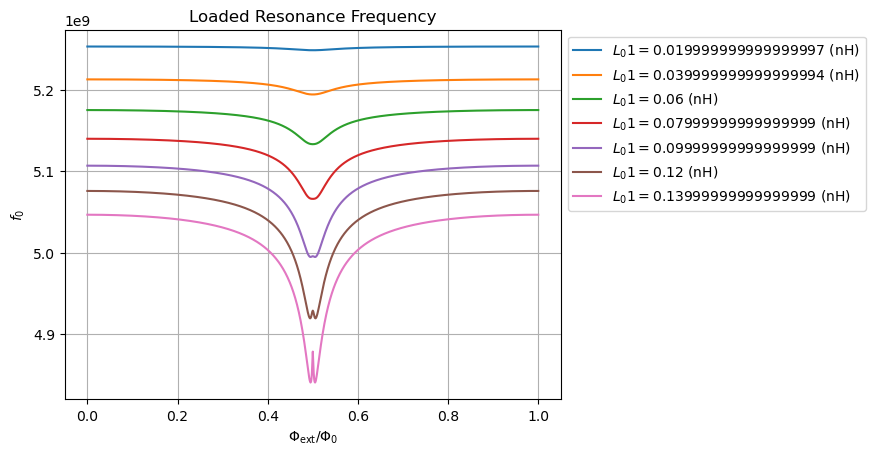

In [89]:
for i in range(len(L01_vals)):
    plt.plot(phi_ext/(2*np.pi), f0_array_L01[:,i], label = f'$L_01 = {L01_vals[i]/1e-9}$ (nH)')
    
plt.xlabel(r'$\Phi_{\rm ext}/\Phi_0$')
plt.ylabel(r'$f_0$')
plt.title(r"Loaded Resonance Frequency")
plt.grid(True)
plt.legend(loc = 'upper left', bbox_to_anchor=(1, 1))
plt.show()

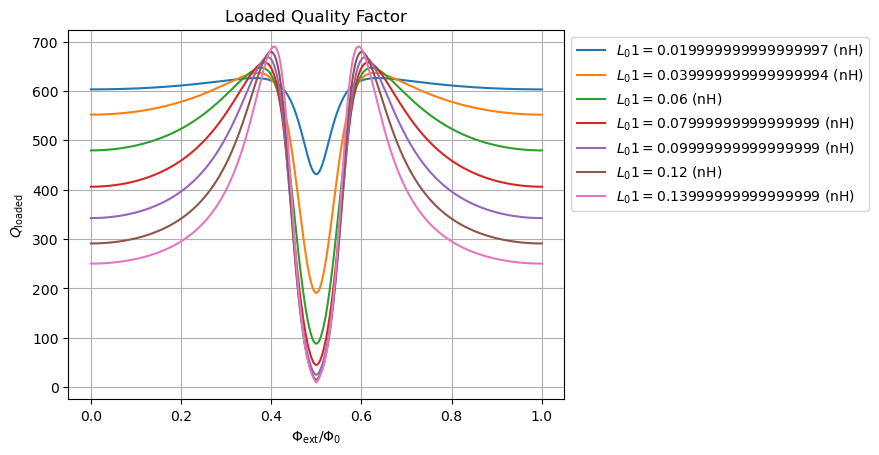

In [90]:
for i in range(len(L01_vals)):
    plt.plot(phi_ext/(2*np.pi), q_loaded_array_L01[:,i], label = f'$L_01 = {L01_vals[i]/1e-9}$ (nH)')
    
plt.xlabel(r'$\Phi_{\rm ext}/\Phi_0$')
plt.ylabel(r'$Q_{\rm loaded}$')
plt.title(r"Loaded Quality Factor")
plt.grid(True)
plt.legend(loc = 'upper left', bbox_to_anchor=(1, 1))
plt.show()

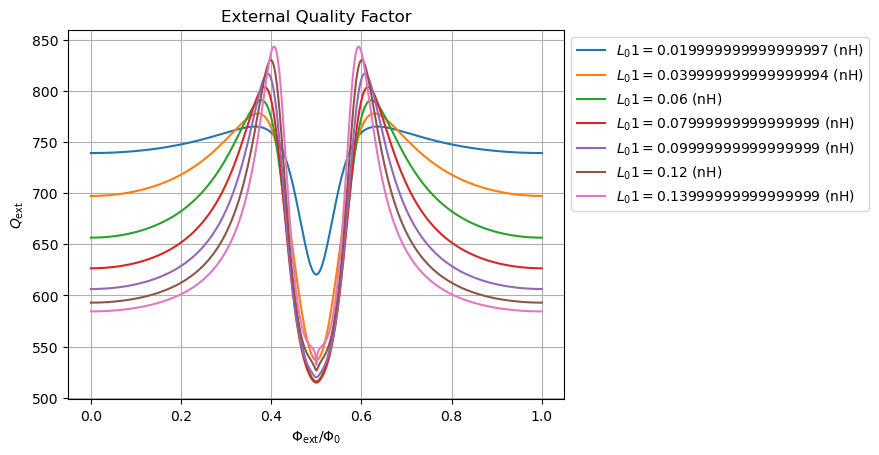

In [91]:
for i in range(len(L01_vals)):
    plt.plot(phi_ext/(2*np.pi), q_external_array_L01[:,i], label = f'$L_01 = {L01_vals[i]/1e-9}$ (nH)')
    
plt.xlabel(r'$\Phi_{\rm ext}/\Phi_0$')
plt.ylabel(r'$Q_{\rm ext}$')
plt.title(r"External Quality Factor")
plt.grid(True)
plt.legend(loc = 'upper left', bbox_to_anchor=(1, 1))
plt.show()

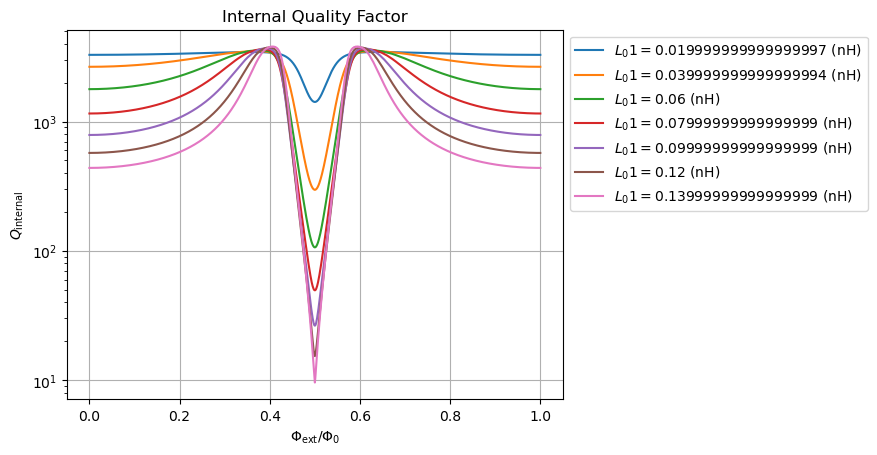

In [92]:
for i in range(len(L01_vals)):
    plt.semilogy(phi_ext/(2*np.pi), q_internal_array_L01[:,i], label = f'$L_01 = {L01_vals[i]/1e-9}$ (nH)')
    
plt.xlabel(r'$\Phi_{\rm ext}/\Phi_0$')
plt.ylabel(r'$Q_{\rm internal}$')
plt.title(r"Internal Quality Factor")
plt.grid(True)
plt.legend(loc = 'upper left', bbox_to_anchor=(1, 1))
plt.show()

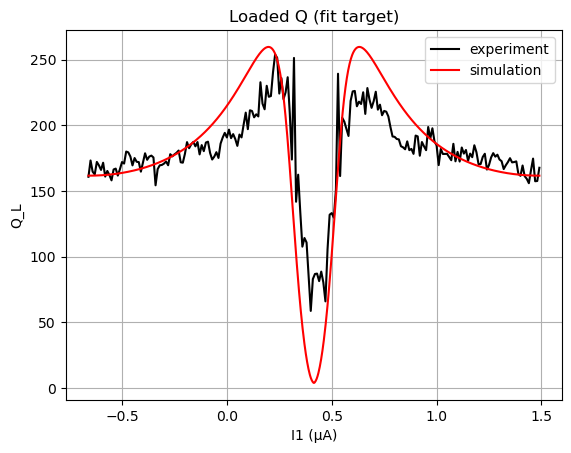

In [77]:
plt.plot(I1_all, Q_L_all, 'k', label = 'experiment')
plt.plot(I_plot_uA, q_loaded_array_L01[:, 5], 'r', label = 'simulation')
plt.xlabel('I1 (μA)')
plt.ylabel('Q_L')
plt.title('Loaded Q (fit target)')
plt.legend()
plt.grid(True)
plt.show()

In [2]:
delta_0 = 1.76*1.38*10**(-23)*1.3
elec_c = 1.6e-19
phi_0 = 2.067*10**(-15)
CT = 100.53e-15
Cc = 8.17e-15
h = 6.626e-34

R_n = (0.5e-9*np.pi**2*delta_0)/(elec_c*phi_0)
R_n_exp = 500
L_T_exp = (R_n_exp*elec_c*phi_0)/(np.pi**2*delta_0)
L_T_exp/1e-9

R_n_hv = 2.5e3
Ic = (np.pi*delta_0)/(2*elec_c*R_n_hv)
Ej0 = (phi_0*Ic)/(2*np.pi)
Ec = (elec_c**2)/(2*(CT+Cc))
R_n

471.1339459387939

In [24]:
N = 4001
RL = l_f
L01 = 0.09e-9 #1.73333071e-10
L02 = 0.4e-9 #1.73333071e-10
LT = 0.5e-9
C_c_vals = np.linspace(10e-15, 30e-15, 10)
N_L = len(C_c_vals)
R_j = 15 #28.224
delta_sols_Cc = np.zeros((N, N_L))
delta_sols_Cc[0, :] = phi_ext[0]
ZL_vals_Cc = np.zeros((N,N,N_L), dtype = complex)
phi_ext = np.linspace(0, 2*np.pi, N)
f_r = np.linspace(4.5e9, 5.5e9, N) # for frequency sweep
w_r = 2*np.pi*f_r
Z_tot_vals_Cc = np.zeros((N,N,N_L), dtype = complex)
Z_branch_vals_Cc = np.zeros((2,2,N,N,N_L), dtype = complex)
fullM_vals_Cc = np.zeros((2,2,N,N,N_L), dtype = complex)
beta_vals_Cc = np.zeros(N)
#Res = np.array([[1,0],[1/R_j,1]])
S21_vals_Cc = np.zeros((N,N,N_L), dtype = complex)

# for loop for calculating the phase difference for each flux and frequency
for k in range(1, N):
    for l in range(N_L):
        d0 = delta_sols_Cc[k-1, l]
        L_f = ((L01+L02)/LT)
        sol = root(del_sol, d0, args=(L_f, phi_ext[k]))
        delta_sols_Cc[k, l] = sol.x[0]
        
# for loop to calculate S21 for each flux and frequency value
for i in range(N):
    beta_vals_Cc[i] = w_r[i] * np.sqrt(L_l*C_l)
    #ZC_vals[:, :, i] = c_cap(C_c, w_r[i])
    #Z_tline_vals_1[:, :, i] = tline(Z_0, beta_vals[i], TL1)
    #Z_tline_vals_2[:, :, i] = tline(Z_0, beta_vals[i], TL2)
    for j in range(N):
        for k in range(N_L):
            ZL_vals_Cc[i, j, k] = Z_L(L01, L02, LT, delta_sols_Cc[j, k], w_r[i], R_j)
            Z_tot_vals_Cc[i, j, k] = Z_tot(ZL_vals_Cc[i, j, k], Z_0, beta_vals_Cc[i], RL, C_c_vals[k], w_r[i])
            Z_branch_vals_Cc[:, :, i, j, k] = branch(Z_tot_vals_Cc[i,j, k])
            #fullM_vals[:, :, i, j] = ABCD(Z_tline_vals_1[:, :, i], Z_branch_vals[:, :, i, j], Z_tline_vals_2[:, :, i])
            fullM_vals_Cc[:, :, i, j, k] = ABCD(I1, Z_branch_vals_Cc[:, :, i, j, k], I2)
            S21_vals_Cc[i, j, k] = S21(fullM_vals_Cc[0, 0, i, j, k], fullM_vals_Cc[0, 1, i, j, k], fullM_vals_Cc[1, 0, i, j, k], fullM_vals_Cc[1, 1, i, j, k], Z_0)

KeyboardInterrupt: 

In [21]:
q_loaded_array_Cc = np.zeros((N,N_L))
q_internal_array_Cc = np.zeros((N,N_L))
q_external_array_Cc = np.zeros((N,N_L))
f0_array_Cc = np.zeros((N,N_L))

for i in range(N_L):
    q_loaded_array_Cc[:, i], q_internal_array_Cc[:, i], q_external_array_Cc[:, i], f0_array_Cc[:, i] = calculate_q_factors(f_r, S21_vals_Cc[:, :, i])

C:\Users\chowdhf4\AppData\Local\Temp\ipykernel_1160\2541280323.py:38: RuntimeWarning: divide by zero encountered in scalar divide
  Q_L_guess = f0_guess/df_guess
C:\Users\chowdhf4\AppData\Local\Temp\ipykernel_1160\2541280323.py:7: RuntimeWarning: invalid value encountered in scalar multiply
  depth_amplitude = Q_L * Q_e_inv          # = Q_L / Q_e
C:\Users\chowdhf4\AppData\Local\Temp\ipykernel_1160\2541280323.py:8: RuntimeWarning: invalid value encountered in multiply
  lorentz = depth_amplitude / (1 + 4 * Q_L**2 * ((f - f0)/f0)**2)
C:\Users\chowdhf4\AppData\Local\Temp\ipykernel_1160\2541280323.py:8: RuntimeWarning: invalid value encountered in divide
  lorentz = depth_amplitude / (1 + 4 * Q_L**2 * ((f - f0)/f0)**2)
C:\Users\chowdhf4\AppData\Local\Temp\ipykernel_1160\2541280323.py:45: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, _ = curve_fit(lorentzian_dip_power, freq, power,
C:\Users\chowdhf4\AppData\Local\Temp\ipykernel_1160\2541280323.py:49: RuntimeWa

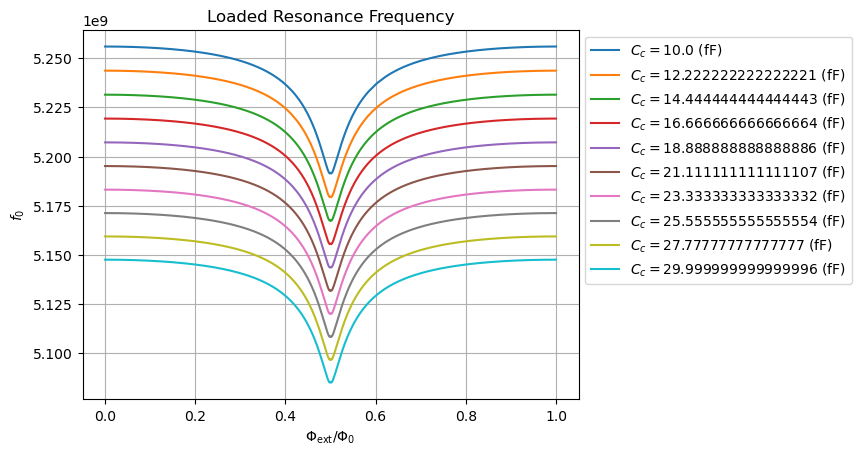

In [22]:
for i in range(len(C_c_vals)):
    plt.plot(phi_ext/(2*np.pi), f0_array_Cc[:,i], label = f'$C_c = {C_c_vals[i]/1e-15}$ (fF)')
    
plt.xlabel(r'$\Phi_{\rm ext}/\Phi_0$')
plt.ylabel(r'$f_0$')
plt.title(r"Loaded Resonance Frequency")
plt.grid(True)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

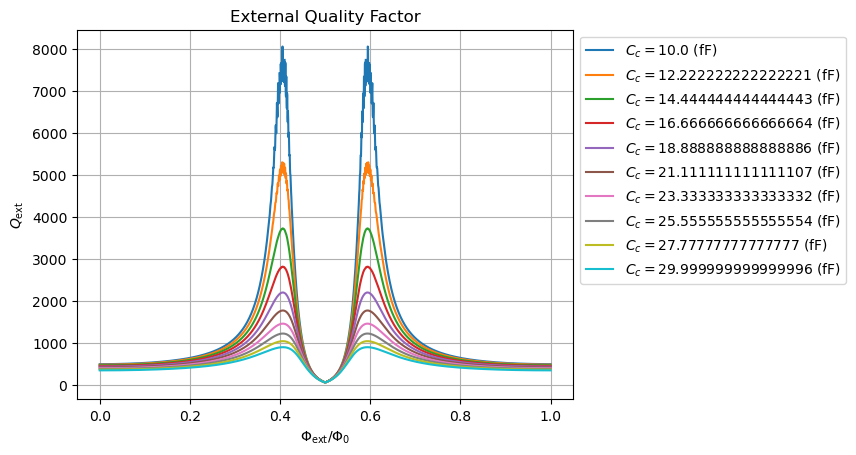

In [23]:
for i in range(len(C_c_vals)):
    plt.plot(phi_ext/(2*np.pi), q_loaded_array_Cc[:,i], label = f'$C_c = {C_c_vals[i]/1e-15}$ (fF)')
    #plt.plot(phi_ext/(2*np.pi), q_external_array_Cc[:,i], label = f'$C_c = {C_c_vals[i]/1e-15}$ (fF)')
    
plt.xlabel(r'$\Phi_{\rm ext}/\Phi_0$')
plt.ylabel(r'$Q_{\rm ext}$')
plt.title(r"External Quality Factor")
plt.grid(True)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

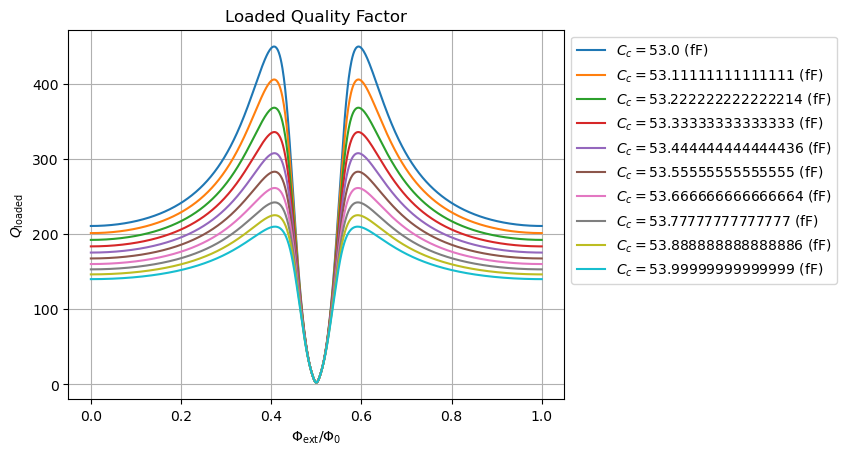

In [80]:
for i in range(len(C_c_vals)):
    plt.plot(phi_ext/(2*np.pi), q_loaded_array_Cc[:,i], label = f'$C_c = {C_c_vals[i]/1e-15}$ (fF)')
    
plt.xlabel(r'$\Phi_{\rm ext}/\Phi_0$')
plt.ylabel(r'$Q_{\rm loaded}$')
plt.title(r"Loaded Quality Factor")
plt.grid(True)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

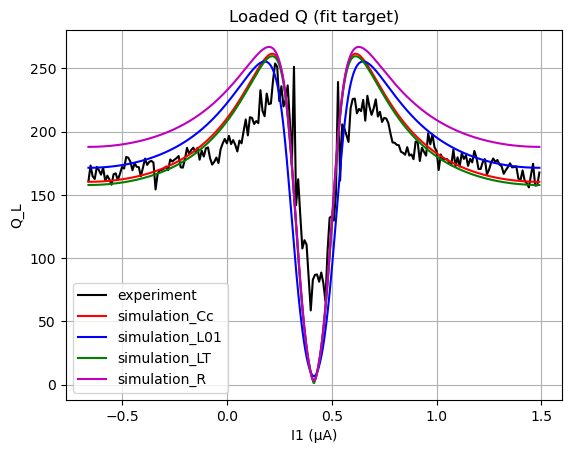

In [81]:
plt.plot(I1_all, Q_L_all, 'k', label = 'experiment')
plt.plot(I_plot_uA, q_loaded_array_Cc[:, 6], 'r', label = 'simulation_Cc')
plt.plot(I_plot_uA, q_loaded_array_L01[:, 3], 'b', label = 'simulation_L01')
plt.plot(I_plot_uA, q_loaded_array_LT[:, 0], 'g', label = 'simulation_LT')
plt.plot(I_plot_uA, q_loaded_array_R[:, 5], 'm', label = 'simulation_R')
plt.xlabel('I1 (μA)')
plt.ylabel('Q_L')
plt.title('Loaded Q (fit target)')
plt.legend()
plt.grid(True)
plt.show()